# Avance 4: Arquitectura en la nube (AWS)
**Proyecto Integrador M2 · FleetLogix · Tomás Babot**

El foco de este avance es **entender, documentar y justificar** la arquitectura, no desplegarla. Para demostrar que el código
funciona sin gastar dinero ni crear recursos reales, todo se ejecuta contra un **AWS simulado en memoria** con la librería
[moto](https://github.com/getmoto/moto): las llamadas de `boto3` son las mismas que en AWS real.

Contenido:
1. Diagrama y flujo de la información.
2. **a)** Qué recursos crean `aws_setup.py` y `lambda_functions.py` y qué hace cada uno.
3. **b)** Explicación de la Lambda `verificar-entrega`.
4. **c)** Explicación de `migrar_datos_postgresql()`.
5. Simulación: se crean los recursos y se prueban las 3 Lambda (versión original vs. versión corregida).
6. Monitoreo (CloudWatch), seguridad y **estimación de costos (< US$ 50/mes)**.

Archivos: `2. Scripts/06_aws_setup.py`, `2. Scripts/lambda_functions/` y `2. Scripts/aws_architecture_diagram.png`.

## 1. Diagrama de la arquitectura

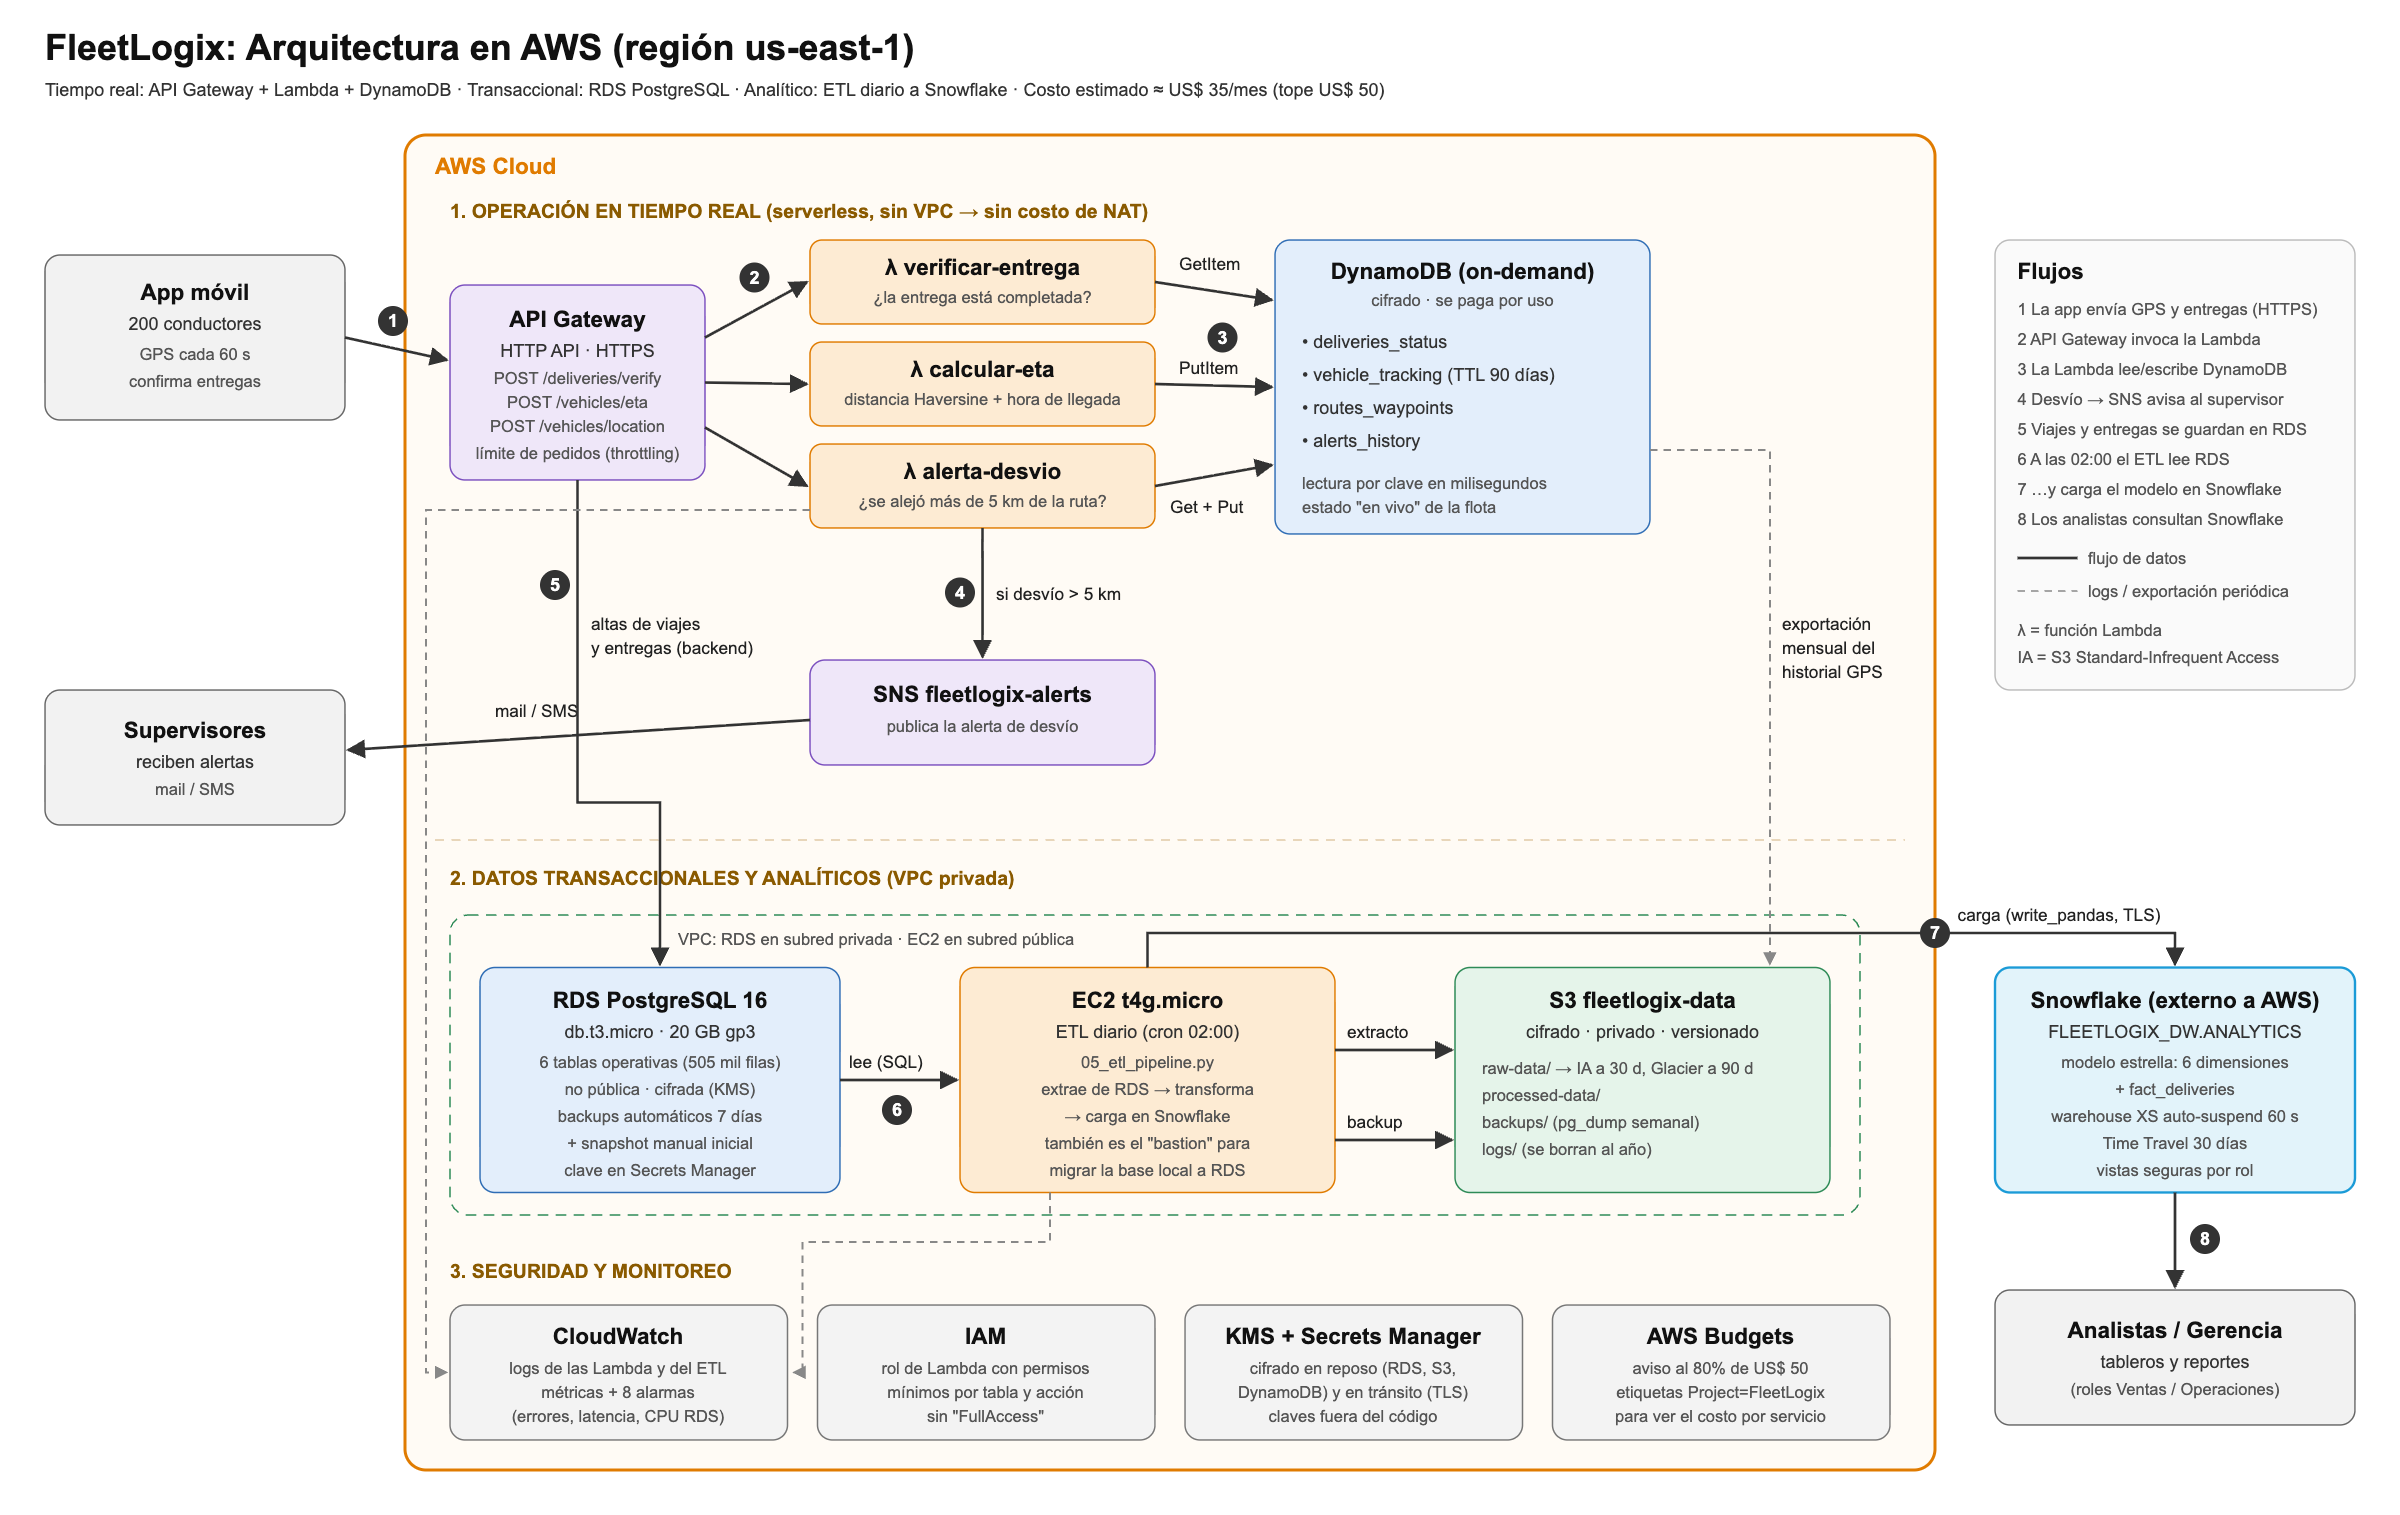

In [1]:
from IPython.display import Image
Image('../2. Scripts/aws_architecture_diagram.png', width=1000)

**Cómo fluye la información**

| Capa | Servicios | Para qué | Por qué este servicio |
|---|---|---|---|
| Tiempo real | API Gateway → Lambda → DynamoDB | la app del conductor manda GPS y confirma entregas; se calcula ETA y se detectan desvíos | **serverless**: se paga por pedido, escala solo y no hay servidores que mantener. DynamoDB responde en milisegundos por clave |
| Alertas | SNS | avisa al supervisor por mail/SMS cuando un camión se desvía | servicio de notificaciones administrado; un tópico puede tener muchos suscriptores |
| Transaccional | RDS PostgreSQL | las 6 tablas operativas (la misma base del Avance 1) | es la misma tecnología que la base local: la migración es directa (`pg_dump` / `pg_restore`). RDS agrega backups, parches y monitoreo |
| Analítica | EC2 (ETL) → Snowflake | el ETL del Avance 3 corre todas las noches | una EC2 chica en subred pública con grupo de seguridad llega a RDS (privada) **y** a Snowflake (internet) sin pagar un NAT Gateway (~US\$ 32/mes) |
| Archivo | S3 | todo el histórico **organizado por fecha** (`raw-data/AAAA/MM/DD/`, `processed-data/AAAA/MM/DD/`), backups y logs | almacenamiento barato y durable; el ciclo de vida mueve lo viejo a clases más baratas |
| Transversal | CloudWatch, IAM, KMS, Secrets Manager, Budgets | monitoreo, permisos, cifrado, claves y control de gasto | servicios nativos, sin costo extra o casi |

**Decisión clave de costos:** las Lambda **no** se ponen dentro de la VPC. DynamoDB, SNS y S3 son servicios públicos de AWS;
si las Lambda estuvieran en la VPC necesitarían un NAT Gateway (≈ US\$ 32/mes + tráfico), que solo eso consumiría casi todo el presupuesto.

**Por qué organizar S3 por fecha:** cada noche el ETL deja el extracto del día en `raw-data/2026/11/17/` y el resultado transformado en `processed-data/2026/11/17/`. Así es fácil encontrar o reprocesar un día puntual, herramientas como Athena pueden leer solo las fechas que hacen falta (se paga por lo que se lee) y la regla de ciclo de vida puede mandar a Glacier lo que tiene más de 90 días.

## 2. a) Recursos que crean los scripts y qué hace cada uno

### `aws_setup.py` (función por función)

| Función | Recurso que crea | Qué hace / para qué sirve |
|---|---|---|
| `crear_rds_postgresql()` | **RDS PostgreSQL** `fleetlogix-db` (db.t3.micro, 20 GB) | base de datos transaccional administrada en la nube; reemplaza al PostgreSQL local. Backups automáticos 7 días |
| `crear_s3_bucket()` | **Bucket S3** `fleetlogix-data` con carpetas `raw-data/`, `processed-data/`, `backups/`, `logs/` y regla de ciclo de vida | almacenar archivos (extractos, backups, logs). La regla pasa `raw-data/` a Glacier a los 90 días para pagar menos |
| `crear_tablas_dynamodb()` | **4 tablas DynamoDB** en modo on-demand | `deliveries_status` (estado actual de cada entrega, clave `delivery_id`), `vehicle_tracking` (historial GPS, clave `vehicle_id` + `timestamp`), `routes_waypoints` (puntos de cada ruta, clave `route_id`), `alerts_history` (alertas, clave `vehicle_id` + `timestamp`) |
| `configurar_backups_automaticos()` | **Snapshot manual** de RDS | copia inicial de la base, además de los backups diarios automáticos |
| `migrar_datos_postgresql()` | **Archivo** `migrate_to_rds.sh` (no crea nada en AWS) | genera el script bash para copiar la base local a RDS (ver punto c) |
| `crear_rol_iam_lambda()` | **Rol IAM** `FleetLogixLambdaRole` | identidad con la que corren las Lambda; define a qué servicios pueden acceder |
| `main()` | archivo `aws_config.json` | guarda los nombres y ARN de lo creado para los pasos siguientes |

### `lambda_functions.py` (3 funciones)

| Función | Disparador | Lee / escribe | Qué hace |
|---|---|---|---|
| `lambda_verificar_entrega` | API Gateway `POST /deliveries/verify` | **lee** `deliveries_status` | responde si una entrega está completada (ver punto b) |
| `lambda_calcular_eta` | API Gateway o EventBridge cada 5 min | **escribe** `vehicle_tracking` | calcula la distancia al destino y la hora estimada de llegada según la velocidad; guarda la lectura |
| `lambda_alerta_desvio` | cada actualización de GPS | **lee** `routes_waypoints`, **escribe** `alerts_history`, **publica** en SNS | busca el punto de la ruta más cercano al camión; si está a más de 5 km, publica una alerta y la guarda |

Ese archivo no crea recursos: es el **código** que se sube a 3 funciones Lambda. El script no crea las Lambda, la API ni el
tópico SNS (que el código usa con un ARN fijo): esos pasos quedan como "próximos pasos".

### Problemas encontrados en los scripts base y cómo se resolvieron

| # | Problema en el script original | Riesgo | Corrección (`06_aws_setup.py` / `lambda_functions/`) |
|---|---|---|---|
| 1 | Contraseña de RDS escrita en el código (`FleetLogix2024!`) | cualquiera con acceso al repositorio entra a la base | `ManageMasterUserPassword=True`: AWS la genera y guarda en **Secrets Manager** |
| 2 | `PubliclyAccessible=True` | la base queda expuesta a internet | `False` + acceso solo desde la VPC; `StorageEncrypted=True` |
| 3 | Snapshot pedido apenas se crea la base | falla: RDS tarda ~10 min en estar disponible | se usa un **waiter** que espera el estado `available` |
| 4 | Ventanas de backup (03-04) y mantenimiento (dom 04-05) se tocan | AWS rechaza la creación | backup 03:00-03:30 y mantenimiento 04:30-05:30 |
| 5 | Políticas `AmazonDynamoDBFullAccess`, `AmazonS3FullAccess`, `AmazonSNSFullAccess` | una Lambda con un error o vulnerada podría borrar cualquier tabla o bucket | **menor privilegio**: solo `GetItem`/`PutItem` en las 4 tablas y `Publish` en el tópico de alertas |
| 6 | S3 sin cifrado ni bloqueo de acceso público | fuga de datos | cifrado por defecto, bloqueo público, versionado |
| 7 | ARN del tópico SNS fijo en el código, con una cuenta de ejemplo | no funciona en otra cuenta | el script crea el tópico y la Lambda lo lee de una variable de entorno |
| 8 | Las Lambda leen los datos directo del evento | con API Gateway los datos llegan como texto en `body` → siempre responde 400 | `_leer_evento()` acepta los dos formatos |
| 9 | Se guardan `float` en DynamoDB (`current_location`, alertas) | DynamoDB no acepta `float` → error 500 | se convierten a `Decimal` |
| 10 | En `alerta_desvio` se restan `Decimal` (de DynamoDB) y `float` | `TypeError` → error 500 | se convierten a `float` antes de calcular |
| 11 | Distancia "111 km por grado" | aproximación (error chico cerca del ecuador, crece con la latitud) | fórmula de **Haversine** |

Los puntos 8, 9 y 10 se **demuestran** en la simulación de la sección 5.

## 3. b) La Lambda `verificar-entrega` en detalle

**Objetivo de negocio:** cuando la app del conductor o el área de atención al cliente pregunta "¿esta entrega ya se hizo?",
responder en milisegundos sin consultar la base transaccional (RDS), que queda libre para la operación.

**Paso a paso del código** (`lambda_functions/verificar_entrega.py`):

1. **Fuera del handler** se crea el cliente `boto3.resource('dynamodb')`. AWS reutiliza el mismo "contenedor" entre invocaciones,
   así que la conexión se crea una sola vez (*warm start*) y las siguientes llamadas son más rápidas.
2. **Recibe el evento.** Con API Gateway (integración *proxy*) los datos llegan como texto JSON en `event['body']`;
   `_leer_evento()` lo convierte a diccionario. Si se prueba desde la consola de Lambda, llegan directo en el evento.
3. **Valida la entrada:** si no viene `delivery_id` responde **400 Bad Request** (error del cliente) sin tocar la base.
4. **Consulta DynamoDB con `get_item`** usando la clave primaria `delivery_id`. Es una lectura directa por clave:
   no recorre la tabla, cuesta 1 unidad de lectura y tarda pocos milisegundos sin importar cuántas entregas haya.
5. **Si no existe** el ítem → **404 Not Found**.
6. **Si existe** → **200 OK** con `is_completed` (`status == 'delivered'`), el estado, el tracking y la fecha de entrega.
7. **Cualquier error inesperado** (tabla inexistente, permisos) → **500** y el detalle queda en **CloudWatch Logs** (el `print`).
8. La respuesta tiene el formato que espera API Gateway: `statusCode`, `headers` y `body` como texto JSON.

**Permisos que necesita:** solo `dynamodb:GetItem` sobre `deliveries_status` y escribir logs. No puede escribir ni borrar nada.

**Quién mantiene actualizada `deliveries_status`:** cuando el conductor confirma una entrega, el backend la registra en RDS
(registro oficial) y actualiza el ítem en DynamoDB (estado "en vivo"). RDS es la fuente de verdad; DynamoDB es una copia rápida para consultas.

## 4. c) `migrar_datos_postgresql()` en detalle

**Qué hace:** **no migra nada por sí misma**. Escribe un archivo `migrate_to_rds.sh` con los comandos para copiar la base
local a RDS, y le indica al usuario que lo ejecute (`bash migrate_to_rds.sh`). Esto tiene sentido porque la migración
necesita que RDS ya esté disponible (~10 min después de crearlo) y conviene correrla a mano, mirando el resultado.

**El script original hace 3 pasos:**

| Paso | Comando | Qué hace |
|---|---|---|
| 1 | `pg_dump -h localhost -U postgres -d fleetlogix -f fleetlogix_dump.sql` | exporta la base local completa (estructura + datos) a un archivo SQL de texto |
| 2 | `psql -h <RDS> -U fleetlogix_admin -c "CREATE DATABASE fleetlogix;"` | crea la base vacía en RDS |
| 3 | `psql -h <RDS> -U fleetlogix_admin -d fleetlogix -f fleetlogix_dump.sql` | ejecuta el archivo en RDS: crea las tablas, carga los datos y los índices |

**Problemas del original y mejoras aplicadas en `06_aws_setup.py`:**
- El paso 2 se conecta **sin indicar base** (`-d`), entonces psql intenta entrar a una base llamada como el usuario, que no existe → falla.
  Ahora se conecta a la base `postgres` y crea `fleetlogix` solo si no existe (en el script nuevo además `create_db_instance` ya la crea con `DBName`).
- El dump guarda como dueño de las tablas al usuario local `postgres`, que en RDS no existe → errores. Le agregué `--no-owner --no-privileges`.
- Formato **custom** (`--format=custom`, comprimido) y restauración con `pg_restore --jobs=4` (4 procesos en paralelo, más rápido).
- `set -e`: si un paso falla, el script se detiene (no sigue restaurando a medias).
- El endpoint y la contraseña se pasan por **variables de entorno** (la clave sale de Secrets Manager), no quedan escritos en el archivo.
- Como RDS ya **no es pública**, el script se corre desde la EC2 de la VPC (que funciona como *bastion*).
- Al final **verifica** contando filas en RDS, para comparar con la base local (505.650 registros).

**Tiempo estimado:** la base pesa unos cientos de MB; el dump y la restauración llevan pocos minutos. Para no perder datos
nuevos durante la migración, se hace en una ventana sin operación (de madrugada) o se repite un dump incremental al final.

## 5. Simulación con moto (AWS en memoria, sin costo)

In [2]:
import os, sys, json, importlib.util
from decimal import Decimal
import pandas as pd
import psycopg2

# Credenciales FALSAS: moto intercepta todas las llamadas, nada sale a AWS
os.environ.update(AWS_ACCESS_KEY_ID='testing', AWS_SECRET_ACCESS_KEY='testing', AWS_SESSION_TOKEN='testing',
                  AWS_DEFAULT_REGION='us-east-1', AWS_REGION='us-east-1', MOTO_IAM_LOAD_MANAGED_POLICIES='true')
from moto import mock_aws
import boto3

simulacion = mock_aws()
simulacion.start()
print('Cuenta simulada:', boto3.client('sts').get_caller_identity()['Account'])

Cuenta simulada: 123456789012


### 5.1 Crear la infraestructura con `06_aws_setup.py`

In [3]:
os.makedirs('../3. Documentación/aws_simulacion', exist_ok=True)
os.chdir('../3. Documentación/aws_simulacion')          # aws_config.json y migrate_to_rds.sh quedan acá
spec = importlib.util.spec_from_file_location('aws_setup', '../../2. Scripts/06_aws_setup.py')
aws_setup = importlib.util.module_from_spec(spec)
spec.loader.exec_module(aws_setup)
config = aws_setup.main(email_supervisor='supervisor@fleetlogix.example')
os.chdir('../../1. Notebooks')

FLEETLOGIX - Configuración AWS


Creando RDS PostgreSQL...


  RDS creado: fleetlogix-db
Creando bucket S3...
  Bucket listo: fleetlogix-data
Creando tablas DynamoDB...


  Tabla creada: deliveries_status
  Tabla creada: vehicle_tracking
  Tabla creada: routes_waypoints
  Tabla creada: alerts_history
Creando tópico SNS de alertas...


  Tópico: arn:aws:sns:us-east-1:123456789012:fleetlogix-alerts
Configurando backups...
  Snapshot inicial: fleetlogix-initial-20261118000419 (más backups automáticos con retención de 7 días)
Generando script de migración...
  Script creado: migrate_to_rds.sh  (ejecutar: RDS_ENDPOINT=... RDS_PASSWORD=... bash migrate_to_rds.sh)
Creando rol IAM para Lambda...


  Rol: arn:aws:iam::123456789012:role/FleetLogixLambdaRole

Configuración guardada en aws_config.json
Próximos pasos: correr migrate_to_rds.sh, desplegar las 3 Lambda con este rol,
crear la API en API Gateway y las alarmas de CloudWatch (ver Arquitectura_Tecnica.pdf).


In [4]:
rds = boto3.client('rds').describe_db_instances()['DBInstances'][0]
s3 = boto3.client('s3')
iam = boto3.client('iam')
resumen = {
    'RDS público': rds['PubliclyAccessible'],
    'RDS cifrado': rds['StorageEncrypted'],
    'RDS versión': rds['EngineVersion'],
    'RDS retención de backups (días)': rds['BackupRetentionPeriod'],
    'Snapshots': len(boto3.client('rds').describe_db_snapshots()['DBSnapshots']),
    'S3 cifrado': s3.get_bucket_encryption(Bucket='fleetlogix-data')['ServerSideEncryptionConfiguration']['Rules'][0]['ApplyServerSideEncryptionByDefault']['SSEAlgorithm'],
    'S3 bloqueo público': all(s3.get_public_access_block(Bucket='fleetlogix-data')['PublicAccessBlockConfiguration'].values()),
    'S3 carpetas': [o['Key'] for o in s3.list_objects_v2(Bucket='fleetlogix-data')['Contents']],
    'Tablas DynamoDB': boto3.client('dynamodb').list_tables()['TableNames'],
    'Tópico SNS': config['alerts_topic_arn'],
    'Políticas administradas del rol': [p['PolicyName'] for p in iam.list_attached_role_policies(RoleName='FleetLogixLambdaRole')['AttachedPolicies']],
}
pd.Series(resumen, name='valor').to_frame()

,valor
RDS público,False
RDS cifrado,True
RDS versión,16.4
RDS retención de backups (días),7
Snapshots,2
S3 cifrado,AES256
S3 bloqueo público,True
S3 carpetas,"[backups/, logs/, processed-data/, raw-data/]"
Tablas DynamoDB,"[deliveries_status, vehicle_tracking, routes_w..."
Tópico SNS,arn:aws:sns:us-east-1:123456789012:fleetlogix-...


In [5]:
politica = iam.get_role_policy(RoleName='FleetLogixLambdaRole', PolicyName='FleetLogixMinimo')['PolicyDocument']
pd.DataFrame([{'permiso': s['Sid'], 'acciones': s['Action'], 'recursos': [r.split(':')[-1] for r in s['Resource']]}
              for s in politica['Statement']])

,permiso,acciones,recursos
0,LeerEntregasYRutas,[dynamodb:GetItem],"[table/deliveries_status, table/routes_waypoints]"
1,GuardarGPSyAlertas,[dynamodb:PutItem],"[table/vehicle_tracking, table/alerts_history]"
2,PublicarAlertas,[sns:Publish],[fleetlogix-alerts]


In [6]:
print(open('../3. Documentación/aws_simulacion/migrate_to_rds.sh').read())

#!/bin/bash
# Migración PostgreSQL local -> RDS. Se corre desde una máquina con acceso a la VPC
# (por ejemplo un bastion o con VPN), porque RDS no es público.
set -e   # si un paso falla, se corta (no seguir restaurando a medias)

LOCAL_DB="fleetlogix"
LOCAL_USER="${LOCAL_USER:-postgres}"
RDS_ENDPOINT="${RDS_ENDPOINT:?Definir RDS_ENDPOINT}"   # se obtiene de la consola o de describe-db-instances
RDS_USER="fleetlogix_admin"
RDS_DB="fleetlogix"
# La clave se lee de Secrets Manager y se pasa por variable (no queda escrita en el archivo)
export PGPASSWORD="${RDS_PASSWORD:?Definir RDS_PASSWORD}"

echo "1. Exportando la base local (formato comprimido, sin dueños locales)..."
pg_dump -h localhost -U "$LOCAL_USER" -d "$LOCAL_DB" --format=custom --no-owner --no-privileges -f fleetlogix.dump

echo "2. Creando la base en RDS si no existe (conectando a la base 'postgres')..."
psql -h "$RDS_ENDPOINT" -U "$RDS_USER" -d postgres -tc "SELECT 1 FROM pg_database WHERE datname = '$RDS_DB'" | grep -q 1 \

### 5.2 Cargar datos de prueba en DynamoDB
- `deliveries_status`: 1.000 entregas reales de PostgreSQL (incluidas las que siguen pendientes).
- `routes_waypoints`: cada ruta como 21 puntos entre las coordenadas reales de la ciudad de origen y la de destino (simplificación: línea recta).

In [7]:
import warnings
# pandas avisa que solo prueba read_sql con SQLAlchemy; con psycopg2 funciona bien
warnings.filterwarnings('ignore', message='pandas only supports SQLAlchemy')

from dotenv import load_dotenv
load_dotenv('../.env')
pg = psycopg2.connect(host=os.getenv('PGHOST', 'localhost'), dbname=os.getenv('PGDATABASE', 'fleetlogix'),
                      user=os.getenv('PGUSER', os.getenv('USER')), password=os.getenv('PGPASSWORD', ''))
entregas = pd.read_sql('''
    (SELECT delivery_id, tracking_number, delivery_status, delivered_datetime FROM deliveries WHERE delivery_status = 'pending')
    UNION ALL
    (SELECT delivery_id, tracking_number, delivery_status, delivered_datetime FROM deliveries WHERE delivery_status = 'delivered'
     ORDER BY delivery_id DESC
     LIMIT 1000 - (SELECT COUNT(*) FROM deliveries WHERE delivery_status = 'pending'))   -- 1.000 en total
''', pg)
rutas = pd.read_sql('SELECT route_id, route_code, origin_city, destination_city, distance_km FROM routes', pg)
pg.close()

dynamo = boto3.resource('dynamodb')
with dynamo.Table('deliveries_status').batch_writer() as lote:
    for e in entregas.itertuples():
        lote.put_item(Item={'delivery_id': str(e.delivery_id), 'tracking_number': e.tracking_number,
                            'status': e.delivery_status, 'delivered_datetime': str(e.delivered_datetime or '')})

CIUDADES = {'Bogotá': (4.7110, -74.0721), 'Medellín': (6.2442, -75.5812), 'Cali': (3.4516, -76.5320),
            'Barranquilla': (10.9639, -74.7964), 'Cartagena': (10.3910, -75.4794)}

def puntos_ruta(origen, destino, n=21):
    (la1, lo1), (la2, lo2) = CIUDADES[origen], CIUDADES[destino]
    return [{'lat': Decimal(str(round(la1 + (la2 - la1) * i / (n - 1), 5))),
             'lon': Decimal(str(round(lo1 + (lo2 - lo1) * i / (n - 1), 5)))} for i in range(n)]

with dynamo.Table('routes_waypoints').batch_writer() as lote:
    for r in rutas.itertuples():
        lote.put_item(Item={'route_id': str(r.route_id), 'route_code': r.route_code,
                            'waypoints': puntos_ruta(r.origin_city, r.destination_city)})

print('deliveries_status:', dynamo.Table('deliveries_status').scan(Select='COUNT')['Count'], 'ítems')
print('routes_waypoints :', dynamo.Table('routes_waypoints').scan(Select='COUNT')['Count'], 'rutas')
ruta_demo = rutas[(rutas.origin_city == 'Bogotá') & (rutas.destination_city == 'Medellín')].iloc[0]
ruta_demo

deliveries_status: 1000 ítems
routes_waypoints : 50 rutas


route_id                   1
route_code              R001
origin_city           Bogotá
destination_city    Medellín
distance_km           439.06
Name: 0, dtype: object

### 5.3 Probar las 3 Lambda corregidas con eventos como los de API Gateway
Para verificar que la alerta **realmente llega**, se suscribe una cola SQS al tópico SNS (en AWS real sería el mail del supervisor).

In [8]:
sqs = boto3.client('sqs')
cola = sqs.create_queue(QueueName='buzon-supervisor')['QueueUrl']
cola_arn = sqs.get_queue_attributes(QueueUrl=cola, AttributeNames=['QueueArn'])['Attributes']['QueueArn']
boto3.client('sns').subscribe(TopicArn=config['alerts_topic_arn'], Protocol='sqs', Endpoint=cola_arn)

# Las Lambda leen el ARN del tópico de una variable de entorno (como se configuraría en AWS)
os.environ['ALERTS_TOPIC_ARN'] = config['alerts_topic_arn']
sys.path.insert(0, '../2. Scripts/lambda_functions')
import verificar_entrega, calcular_eta, alerta_desvio

def api_gateway(datos):
    '''Arma un evento como el que manda API Gateway (integración proxy): los datos van como texto en body.'''
    return {'httpMethod': 'POST', 'headers': {'Content-Type': 'application/json'}, 'body': json.dumps(datos)}

def mostrar(respuesta):
    return {'statusCode': respuesta['statusCode'], **json.loads(respuesta['body'])}

In [9]:
id_entregada = str(entregas.loc[entregas.delivery_status == 'delivered', 'delivery_id'].iloc[0])
id_pendiente = str(entregas.loc[entregas.delivery_status == 'pending', 'delivery_id'].iloc[0])
casos = {
    'entrega completada': {'delivery_id': id_entregada},
    'entrega pendiente': {'delivery_id': id_pendiente},
    'entrega que no existe': {'delivery_id': '999999999'},
    'sin delivery_id': {},
}
pd.DataFrame([{'caso': caso, **mostrar(verificar_entrega.lambda_handler(api_gateway(datos), None))}
              for caso, datos in casos.items()])

,caso,statusCode,delivery_id,tracking_number,is_completed,status,delivered_datetime,error
0,entrega completada,200,400000,FL202600400000,True,delivered,2026-11-17 04:20:00,NaN
1,entrega pendiente,200,399955,FL202600399955,False,pending,NaT,NaN
2,entrega que no existe,404,999999999,NaN,NaN,NaN,NaN,Entrega no encontrada
3,sin delivery_id,400,NaN,NaN,NaN,NaN,NaN,delivery_id es requerido


In [10]:
bogota, medellin = CIUDADES['Bogotá'], CIUDADES['Medellín']
mitad = {'lat': (bogota[0] + medellin[0]) / 2, 'lon': (bogota[1] + medellin[1]) / 2}
casos_eta = {
    'a mitad de ruta, 60 km/h': {'vehicle_id': 'V-017', 'current_location': mitad, 'destination': {'lat': medellin[0], 'lon': medellin[1]}, 'current_speed_kmh': 60},
    'vehículo detenido': {'vehicle_id': 'V-018', 'current_location': mitad, 'destination': {'lat': medellin[0], 'lon': medellin[1]}, 'current_speed_kmh': 0},
    'falta el destino': {'vehicle_id': 'V-019', 'current_location': mitad},
}
display(pd.DataFrame([{'caso': caso, **mostrar(calcular_eta.lambda_handler(api_gateway(datos), None))}
                      for caso, datos in casos_eta.items()]))
print('Lecturas guardadas en vehicle_tracking:', dynamo.Table('vehicle_tracking').scan(Select='COUNT')['Count'])

,caso,statusCode,vehicle_id,distance_remaining_km,estimated_minutes,eta,error
0,"a mitad de ruta, 60 km/h",200,V-017,119.3,119.0,2026-11-18T05:03:21.113713+00:00,NaN
1,vehículo detenido,200,V-018,119.3,NaN,No disponible,NaN
2,falta el destino,400,NaN,NaN,NaN,NaN,"Faltan parámetros: vehicle_id, current_locatio..."


Lecturas guardadas en vehicle_tracking: 2


In [11]:
punto_ruta = {'lat': mitad['lat'] + 0.01, 'lon': mitad['lon']}          # ~1 km de la ruta
desviado = {'lat': mitad['lat'] + 0.20, 'lon': mitad['lon'] + 0.15}     # ~25 km de la ruta
base = {'vehicle_id': 'V-017', 'driver_id': '42', 'route_id': str(ruta_demo.route_id)}
casos_desvio = {
    'en ruta (≈1 km)': {**base, 'current_location': punto_ruta},
    'desviado (≈25 km)': {**base, 'current_location': desviado},
    'ruta inexistente': {**base, 'route_id': '9999', 'current_location': punto_ruta},
}
pd.DataFrame([{'caso': caso, **mostrar(alerta_desvio.lambda_handler(api_gateway(datos), None))}
              for caso, datos in casos_desvio.items()])

,caso,statusCode,vehicle_id,is_deviated,deviation_km,alert_sent,threshold_km,error,route_id
0,en ruta (≈1 km),200,V-017,False,1.11,False,5.0,NaN,NaN
1,desviado (≈25 km),200,V-017,True,27.75,True,5.0,NaN,NaN
2,ruta inexistente,404,NaN,NaN,NaN,NaN,NaN,Ruta no encontrada,9999


In [12]:
mensajes = sqs.receive_message(QueueUrl=cola, MaxNumberOfMessages=10).get('Messages', [])
for m in mensajes:
    sobre = json.loads(m['Body'])
    print('Asunto :', sobre['Subject'])
    print('Mensaje:', sobre['Message'])
print('\nAlertas guardadas en alerts_history:', dynamo.Table('alerts_history').scan(Select='COUNT')['Count'])

Asunto : FleetLogix: desvío de ruta detectado
Mensaje: {"vehicle_id": "V-017", "timestamp": "2026-11-18T03:04:21.166325+00:00", "driver_id": "42", "route_id": "1", "deviation_km": 27.75, "current_location": {"lat": 5.677600000000001, "lon": -74.67665}, "alert_type": "ROUTE_DEVIATION"}

Alertas guardadas en alerts_history: 1


### 5.4 Las mismas pruebas con el código ORIGINAL (`A4-lambda_functions.py`)
Así se demuestra por qué hubo que corregirlo.

In [13]:
spec = importlib.util.spec_from_file_location('original', '../3. Documentación/aws_simulacion/lambda_functions_original_henry.py')
original = importlib.util.module_from_spec(spec)
spec.loader.exec_module(original)

pruebas = [
    ('verificar - evento de API Gateway', original.lambda_verificar_entrega, api_gateway({'delivery_id': id_entregada})),
    ('verificar - evento directo', original.lambda_verificar_entrega, {'delivery_id': id_entregada}),
    ('calcular ETA - evento directo', original.lambda_calcular_eta, casos_eta['a mitad de ruta, 60 km/h']),
    ('alerta desvío - evento directo', original.lambda_alerta_desvio, casos_desvio['desviado (≈25 km)']),
]
filas = []
for nombre, funcion, evento in pruebas:
    r = funcion(evento, None)
    filas.append({'prueba': nombre, 'statusCode': r['statusCode'], 'respuesta': r['body'][:110]})
pd.DataFrame(filas)

,prueba,statusCode,respuesta
0,verificar - evento de API Gateway,400,"{""error"": ""delivery_id es requerido""}"
1,verificar - evento directo,200,"{""delivery_id"": ""400000"", ""tracking_number"": ""..."
2,calcular ETA - evento directo,500,"{""error"": ""Float types are not supported. Use ..."
3,alerta desvío - evento directo,500,"{""error"": ""unsupported operand type(s) for -: ..."


**Resultado:** con un evento real de API Gateway la Lambda original responde **400** (no encuentra `delivery_id` porque viene dentro de `body`).
`calcular_eta` y `alerta_desvio` fallan con **500**: DynamoDB no acepta `float` y no se pueden restar `Decimal` y `float`.
Solo `verificar_entrega` funciona, y únicamente si se la prueba desde la consola. Las versiones corregidas responden bien en todos los casos.

In [14]:
from math import radians, sin, cos, asin, sqrt
def haversine(a, b):
    la1, lo1, la2, lo2 = map(radians, [a[0], a[1], b[0], b[1]])
    h = sin((la2 - la1) / 2) ** 2 + cos(la1) * cos(la2) * sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * asin(sqrt(h))
aprox_111 = lambda a, b: sqrt((a[0] - b[0]) ** 2 + (a[1] - b[1]) ** 2) * 111

pd.DataFrame([{'tramo': f'{o} → {d}', 'haversine_km': round(haversine(CIUDADES[o], CIUDADES[d]), 1),
               'aprox_111_km': round(aprox_111(CIUDADES[o], CIUDADES[d]), 1)}
              for o, d in [('Bogotá', 'Medellín'), ('Bogotá', 'Barranquilla'), ('Cali', 'Cartagena')]]
             ).assign(error_pct=lambda t: (100 * (t.aprox_111_km / t.haversine_km - 1)).round(2))

,tramo,haversine_km,aprox_111_km,error_pct
0,Bogotá → Medellín,238.7,238.8,0.04
1,Bogotá → Barranquilla,699.8,698.7,-0.16
2,Cali → Cartagena,780.3,779.1,-0.15


En Colombia (cerca del ecuador) la aproximación de 111 km por grado tiene un error chico (menos de 1%). Igual se usa Haversine,
que es exacta a cualquier latitud y no cuesta más.

## 6. Monitoreo, seguridad y costos
### 6.1 Métricas y alarmas de CloudWatch
Creé 8 alarmas que avisan al mismo tópico SNS. Todas usan métricas que AWS publica solo (sin código extra).

In [15]:
cw = boto3.client('cloudwatch')
alarmas = [
    # (nombre, namespace, métrica, dimensión, estadística, umbral, comparación, por qué)
    ('lambda-verificar-errores', 'AWS/Lambda', 'Errors', {'FunctionName': 'fleetlogix-verificar-entrega'}, 'Sum', 5, 'GreaterThanThreshold', 'la app no puede confirmar entregas'),
    ('lambda-eta-errores', 'AWS/Lambda', 'Errors', {'FunctionName': 'fleetlogix-calcular-eta'}, 'Sum', 5, 'GreaterThanThreshold', 'clientes sin hora de llegada'),
    ('lambda-desvio-errores', 'AWS/Lambda', 'Errors', {'FunctionName': 'fleetlogix-alerta-desvio'}, 'Sum', 5, 'GreaterThanThreshold', 'desvíos que no se detectan'),
    ('lambda-desvio-duracion', 'AWS/Lambda', 'Duration', {'FunctionName': 'fleetlogix-alerta-desvio'}, 'Average', 2000, 'GreaterThanThreshold', 'respuesta lenta (> 2 s) y más costo'),
    ('api-errores-5xx', 'AWS/ApiGateway', '5xx', {'ApiId': 'fleetlogix-api'}, 'Sum', 10, 'GreaterThanThreshold', 'la API falla para los conductores'),
    ('rds-cpu-alta', 'AWS/RDS', 'CPUUtilization', {'DBInstanceIdentifier': 'fleetlogix-db'}, 'Average', 80, 'GreaterThanThreshold', 'base saturada: evaluar un tamaño mayor'),
    ('rds-poco-espacio', 'AWS/RDS', 'FreeStorageSpace', {'DBInstanceIdentifier': 'fleetlogix-db'}, 'Average', 2 * 1024**3, 'LessThanThreshold', 'quedan menos de 2 GB de disco'),
    ('dynamodb-throttling', 'AWS/DynamoDB', 'ThrottledRequests', {'TableName': 'vehicle_tracking'}, 'Sum', 0, 'GreaterThanThreshold', 'pedidos rechazados por exceso de carga'),
]
for nombre, ns, metrica, dim, est, umbral, comp, _ in alarmas:
    cw.put_metric_alarm(AlarmName=f'fleetlogix-{nombre}', Namespace=ns, MetricName=metrica,
                        Dimensions=[{'Name': k, 'Value': v} for k, v in dim.items()],
                        Statistic=est, Period=300, EvaluationPeriods=1, Threshold=umbral,
                        ComparisonOperator=comp, AlarmActions=[config['alerts_topic_arn']])

motivos = {f'fleetlogix-{a[0]}': a[-1] for a in alarmas}
creadas = cw.describe_alarms()['MetricAlarms']
pd.DataFrame([{'alarma': a['AlarmName'], 'métrica': f"{a['Namespace']} / {a['MetricName']}",
               'condición': f"{a['Statistic']} {'>' if a['ComparisonOperator'].startswith('Greater') else '<'} {a['Threshold']:g} (5 min)",
               'motivo': motivos[a['AlarmName']]} for a in creadas])

,alarma,métrica,condición,motivo
0,fleetlogix-lambda-verificar-errores,AWS/Lambda / Errors,Sum > 5 (5 min),la app no puede confirmar entregas
1,fleetlogix-lambda-eta-errores,AWS/Lambda / Errors,Sum > 5 (5 min),clientes sin hora de llegada
2,fleetlogix-lambda-desvio-errores,AWS/Lambda / Errors,Sum > 5 (5 min),desvíos que no se detectan
3,fleetlogix-lambda-desvio-duracion,AWS/Lambda / Duration,Average > 2000 (5 min),respuesta lenta (> 2 s) y más costo
4,fleetlogix-api-errores-5xx,AWS/ApiGateway / 5xx,Sum > 10 (5 min),la API falla para los conductores
5,fleetlogix-rds-cpu-alta,AWS/RDS / CPUUtilization,Average > 80 (5 min),base saturada: evaluar un tamaño mayor
6,fleetlogix-rds-poco-espacio,AWS/RDS / FreeStorageSpace,Average < 2.14748e+09 (5 min),quedan menos de 2 GB de disco
7,fleetlogix-dynamodb-throttling,AWS/DynamoDB / ThrottledRequests,Sum > 0 (5 min),pedidos rechazados por exceso de carga


Además: **logs** de cada Lambda y del ETL en CloudWatch Logs (retención 30 días), un **dashboard** con invocaciones, errores y
latencia, y **AWS Budgets** con aviso al llegar al 80% de US$ 50.

### 6.2 Seguridad

| Tema | Medida |
|---|---|
| Permisos (IAM) | rol de Lambda con menor privilegio (solo las acciones y tablas que usa, ver 5.1); un usuario/rol distinto para el ETL |
| Red | RDS en subred **privada**, sin IP pública; el grupo de seguridad solo acepta el puerto 5432 desde la EC2 del ETL |
| Cifrado en reposo | RDS (KMS), S3 (SSE), DynamoDB (cifrado por defecto) |
| Cifrado en tránsito | HTTPS en API Gateway; TLS hacia RDS y Snowflake |
| Secretos | contraseña de RDS en **Secrets Manager**; en el proyecto local, credenciales en `.env` y llave de Snowflake en `keys/` (ambos fuera de git) |
| API | límite de pedidos por segundo (*throttling*) y autenticación de la app (API key o Cognito) |
| Backups | RDS: automáticos 7 días + snapshot; S3 versionado; Snowflake: Time Travel 30 días |

### 6.3 Estimación de costos mensuales
**Supuestos de uso:** 200 vehículos, 12 horas de operación por día, 30 días; GPS cada **60 s** (a 80 km/h el camión recorre 1,3 km
por minuto, suficiente para detectar un desvío de 5 km); ETA cada 5 minutos; ~550 entregas por día consultadas 3 veces.
Precios de lista de AWS en us-east-1 (aproximados; verificar con AWS Pricing Calculator).

In [16]:
horas_mes = 730
gps_mes = 200 * 60 * 12 * 30              # una posición por minuto
eta_mes = 200 * 12 * 12 * 30              # cada 5 minutos
verif_mes = 550 * 3 * 30
pedidos = gps_mes + eta_mes + verif_mes

lambda_gb_s = pedidos * 0.15 * 0.125      # 150 ms promedio, 128 MB
costos = [
    ('RDS PostgreSQL db.t3.micro (Single-AZ)', 0.018 * horas_mes, 'US$ 0,018 por hora'),
    ('RDS almacenamiento gp3 20 GB', 20 * 0.115, 'US$ 0,115 por GB; backups hasta 20 GB sin cargo'),
    ('EC2 t4g.micro (ETL + bastion)', 0.0084 * horas_mes, 'US$ 0,0084 por hora'),
    ('EC2 disco EBS gp3 8 GB', 8 * 0.08, 'US$ 0,08 por GB'),
    ('IP pública IPv4 de la EC2', 0.005 * horas_mes, 'US$ 0,005 por hora'),
    ('API Gateway (HTTP API)', pedidos / 1e6 * 1.00, f'{pedidos/1e6:.2f} M pedidos × US$ 1 por millón'),
    ('Lambda: pedidos', max(0, pedidos - 1e6) / 1e6 * 0.20, '1 M gratis por mes; luego US$ 0,20 por millón'),
    ('Lambda: cómputo', max(0, lambda_gb_s - 400_000) * 0.0000166667, f'{lambda_gb_s:,.0f} GB-s (400.000 gratis por mes)'),
    ('DynamoDB escrituras on-demand', (eta_mes + 2 * 550 * 30) / 1e6 * 0.625, 'US$ 0,625 por millón'),
    ('DynamoDB lecturas on-demand', (gps_mes + verif_mes) / 1e6 * 0.125, 'US$ 0,125 por millón'),
    ('DynamoDB almacenamiento', 0.0, '< 1 GB con TTL de 90 días (25 GB gratis)'),
    ('S3 (10 GB + pedidos)', 10 * 0.023 + 0.05, 'US$ 0,023 por GB'),
    ('CloudWatch Logs (~2,6 GB)', 2.6 * 0.50, 'US$ 0,50 por GB ingerido; 8 alarmas dentro de las 10 gratis'),
    ('Secrets Manager (1 secreto)', 0.40, 'US$ 0,40 por secreto'),
    ('SNS (alertas por mail)', 0.0, 'primeros 1.000 mails gratis'),
    ('Transferencia de datos', 0.0, 'primeros 100 GB de salida gratis'),
]
tabla_costos = pd.DataFrame(costos, columns=['servicio', 'usd_mes', 'cálculo'])
tabla_costos['usd_mes'] = tabla_costos['usd_mes'].round(2)
total = tabla_costos['usd_mes'].sum()
tabla_costos.loc[len(tabla_costos)] = ['TOTAL', round(total, 2), f'margen contra el tope de US$ 50: {50 - total:.2f}']
tabla_costos

,servicio,usd_mes,cálculo
0,RDS PostgreSQL db.t3.micro (Single-AZ),13.14,"US$ 0,018 por hora"
1,RDS almacenamiento gp3 20 GB,2.30,"US$ 0,115 por GB; backups hasta 20 GB sin cargo"
2,EC2 t4g.micro (ETL + bastion),6.13,"US$ 0,0084 por hora"
3,EC2 disco EBS gp3 8 GB,0.64,"US$ 0,08 por GB"
4,IP pública IPv4 de la EC2,3.65,"US$ 0,005 por hora"
5,API Gateway (HTTP API),5.23,5.23 M pedidos × US$ 1 por millón
6,Lambda: pedidos,0.85,"1 M gratis por mes; luego US$ 0,20 por millón"
7,Lambda: cómputo,0.00,"98,128 GB-s (400.000 gratis por mes)"
8,DynamoDB escrituras on-demand,0.56,"US$ 0,625 por millón"
9,DynamoDB lecturas on-demand,0.55,"US$ 0,125 por millón"


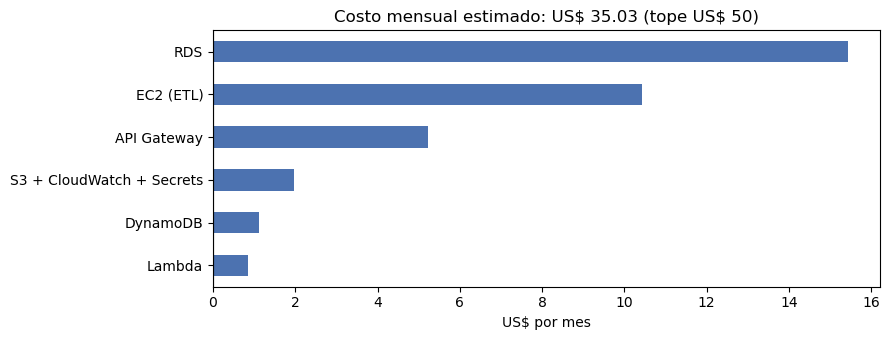

In [17]:
import matplotlib.pyplot as plt
grupos = {'RDS': ['RDS'], 'EC2 (ETL)': ['EC2', 'IP pública'], 'API Gateway': ['API Gateway'], 'Lambda': ['Lambda'],
          'DynamoDB': ['DynamoDB'], 'S3 + CloudWatch + Secrets': ['S3', 'CloudWatch', 'Secrets']}
por_grupo = {g: tabla_costos[tabla_costos['servicio'].str.startswith(tuple(p))]['usd_mes'].sum() for g, p in grupos.items()}
serie = pd.Series(por_grupo).sort_values()
ax = serie.plot(kind='barh', color='#4C72B0', figsize=(9, 3.5))
ax.axvline(0, color='black'); ax.set_xlabel('US$ por mes')
ax.set_title(f'Costo mensual estimado: US\\$ {total:.2f} (tope US\\$ 50)')
plt.tight_layout(); plt.savefig('../3. Documentación/img/costos_aws.png', dpi=150); plt.show()

**Lectura:** el costo fijo (RDS + EC2, ≈ US\$ 26) es casi tres cuartos del total; el componente *serverless* cuesta poco porque se paga por uso.

**Cómo se mantiene bajo US\$ 50 si la operación crece:**
- Si se duplica la flota, solo crecen API Gateway, Lambda y DynamoDB (≈ +US\$ 7): sigue dentro del tope.
- Instancias reservadas (1 año) para RDS y EC2: −30 a −40% sobre su costo.
- Bajar la frecuencia del GPS a 2 minutos fuera de ruta o enviar posiciones en lotes.
- TTL en `vehicle_tracking` y ciclo de vida en S3 para que el almacenamiento no crezca sin límite.
- **No usar NAT Gateway** ni RDS Multi-AZ en esta etapa (cada uno duplicaría el costo). Multi-AZ se evalúa cuando la base sea crítica 24/7.

**Snowflake se paga aparte** (créditos): con el warehouse X-Small que se apaga a los 60 s y un ETL de ~1 minuto por día,
el consumo es de pocos créditos por mes.

In [18]:
simulacion.stop()
print('Simulación terminada: no se creó ningún recurso real en AWS.')

Simulación terminada: no se creó ningún recurso real en AWS.


## 7. Conclusiones del Avance 4

- La arquitectura separa **tiempo real** (API Gateway + Lambda + DynamoDB), **transaccional** (RDS) y **analítica** (ETL → Snowflake),
  cada una con el servicio más adecuado y barato para su carga.
- Respondí las preguntas **a)** recursos de cada script, **b)** funcionamiento de `verificar-entrega` y **c)** migración a RDS,
  y documenté **11 problemas** de los scripts base con su corrección.
- La simulación con moto demuestra que el código corregido funciona de punta a punta (incluida la alerta que llega por SNS)
  y que el original fallaba con eventos reales de API Gateway y al guardar en DynamoDB.
- Costo estimado **≈ US\$ 35/mes**, por debajo del tope de US\$ 50, con monitoreo (8 alarmas), seguridad por capas y backups.